# Fuzzy Logic and a Fuzzy Cognitive Map for Prioritising Citizen-Reported Urban Problems in Bern (v2)

**Seminar of Urban Computing AS2026** — Bill Brandon Chavez Arias, Saadet Yilmaz, Yasmine Alaya

The model ranks citizen reports (potholes, broken streetlights, blocked sidewalks, overflowing bins, …)
by how urgently the city should respond.

| Step | What | Why |
|---|---|---|
| 1 | Citizen report: category, location, linguistic description | Participatory sensing: citizens act as sensors of the city |
| 2 | Spatial context from OpenStreetMap → *Population exposure* | The same defect matters more near a school or a busy stop |
| 3 | Fuzzification of the four inputs (triangular fuzzy numbers) | Reports and expert judgements are vague; fuzzy numbers keep this explicit |
| 4 | Fuzzy Cognitive Map with expert-elicited weights | Factors influence each other; the map is transparent and explainable |
| 5 | Priority = final activation of *Response urgency* | One output concept, no separate "Priority" node |

All model code lives in `fcm_model.py` (shared with the Streamlit interface `app.py`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import fcm_model as m

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

## 1. Concepts

| Code | Concept | Role |
|---|---|---|
| C1 | Severity | **input** — seriousness of the defect |
| C2 | Safety risk | inferred — potential harm to people |
| C3 | Service disruption | inferred — interference with access / services |
| C4 | Population exposure | **input** — how many people are exposed (from city data) |
| C5 | Deterioration | **input** — is it getting worse? |
| C6 | Workaround availability | **input** — is there a safe alternative? (high = good alternative) |
| C7 | Residual public impact | inferred — impact remaining after mitigation |
| C8 | Response urgency | **output** — priority |

**Change from v1:** inputs are the concepts we can *observe* in a report (C1, C4, C5, C6). They are
clamped during inference. C2, C3, C7, C8 are *computed* by the map and start at 0.

## 2. Where the weights come from: expert elicitation with linguistic terms

There is no dataset that tells us "Severity influences Safety risk with strength 0.67". The
standard FCM practice (Kosko 1986; Stylios & Groumpos 2004; Papageorgiou et al.) is:

1. each expert rates each causal link with a **linguistic term** (*weak, medium, strong, …*) and a sign;
2. each term is a **triangular fuzzy number** (a, b, c);
3. the experts' fuzzy numbers are **averaged**, then **defuzzified** with the centroid (a+b+c)/3.

So the weights are not invented numbers: they are the documented, reproducible result of a fuzzy
elicitation procedure, and the *disagreement* between experts is reported too.
`expert_weights.csv` currently holds the team draft (one column). Add one column per expert
(team members, the lecturer, ideally someone from the City of Bern Tiefbauamt) and re-run.

In [2]:
pd.DataFrame(m.WEIGHT_TERMS, index=["a", "b", "c"]).T.assign(centroid=lambda d: d.mean(axis=1).round(3))

,a,b,c,centroid
none,0.00,0.00,0.00,0.000
very_weak,0.00,0.00,0.17,0.057
weak,0.00,0.17,0.33,0.167
moderately_weak,0.17,0.33,0.50,0.333
medium,0.33,0.50,0.67,0.500
moderately_strong,0.50,0.67,0.83,0.667
strong,0.67,0.83,1.00,0.833
very_strong,0.83,1.00,1.00,0.943


In [3]:
elicitation = m.load_elicitation()
edges = m.aggregate_weights(elicitation)
W = m.weight_matrix(edges)
edges[["source", "target", "sign", "n_experts", "tfn", "weight", "disagreement", "rationale"]]

,source,target,sign,n_experts,tfn,weight,disagreement,rationale
0,Severity,Safety_Risk,+,1,"(0.5, 0.67, 0.83)",0.667,0.0,A more severe defect generally increases the p...
1,Severity,Service_Disruption,+,1,"(0.5, 0.67, 0.83)",0.667,0.0,More serious defects are more likely to impair...
2,Safety_Risk,Service_Disruption,+,1,"(0.0, 0.17, 0.33)",0.167,0.0,A dangerous situation can lead to closures or ...
3,Service_Disruption,Safety_Risk,+,1,"(0.0, 0.17, 0.33)",0.167,0.0,"A disrupted service (e.g. failed signal, dark ..."
4,Safety_Risk,Residual_Public_Impact,+,1,"(0.5, 0.67, 0.83)",0.667,0.0,Safety consequences contribute strongly to the...
5,Safety_Risk,Response_Urgency,+,1,"(0.17, 0.33, 0.5)",0.333,0.0,A serious safety risk can require rapid action...
6,Service_Disruption,Residual_Public_Impact,+,1,"(0.5, 0.67, 0.83)",0.667,0.0,Significant interruption of access or services...
7,Population_Exposure,Safety_Risk,+,1,"(0.17, 0.33, 0.5)",0.333,0.0,More exposed people increase the overall poten...
8,Population_Exposure,Residual_Public_Impact,+,1,"(0.5, 0.67, 0.83)",0.667,0.0,The same defect affects far more people in a b...
9,Deterioration,Severity,+,1,"(0.17, 0.33, 0.5)",0.333,0.0,A worsening condition tends to increase the se...


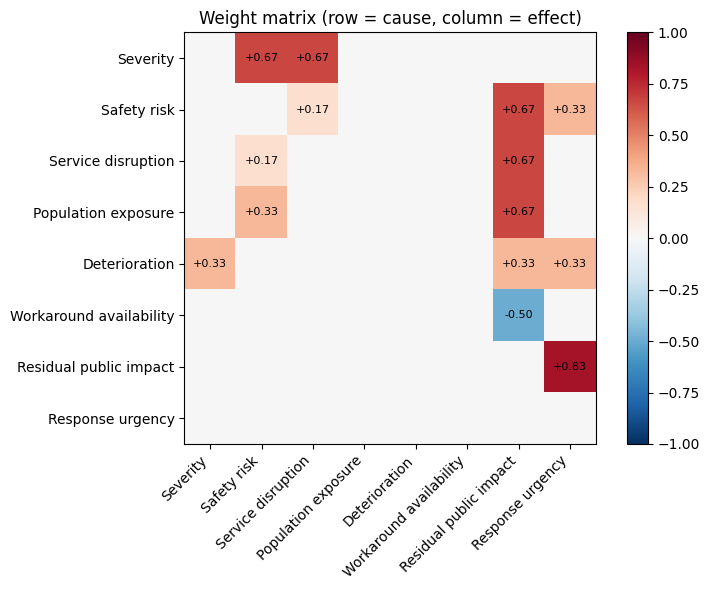

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(W.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(8)); ax.set_xticklabels([m.LABELS[c] for c in m.CONCEPTS], rotation=45, ha="right")
ax.set_yticks(range(8)); ax.set_yticklabels([m.LABELS[c] for c in m.CONCEPTS])
for i in range(8):
    for j in range(8):
        if W.values[i, j]:
            ax.text(j, i, f"{W.values[i, j]:+.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Weight matrix (row = cause, column = effect)")
plt.colorbar(im); plt.tight_layout(); plt.show()

## 3. Fuzzification of the inputs

Each input is assessed with one of five linguistic terms. The centroid of its triangular fuzzy
number is the activation used by the map. The α-cut at 0.5 gives a low/high reading that we
propagate to obtain a **plausible range** for the priority.

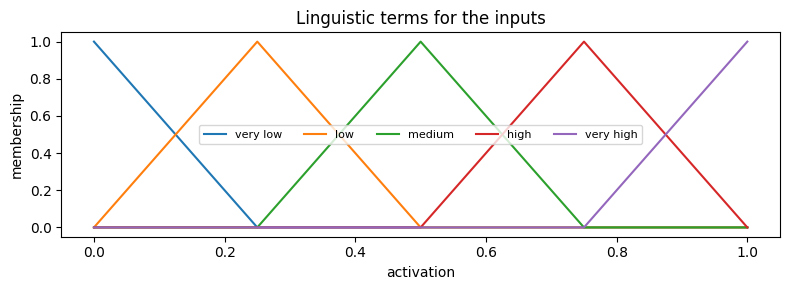

In [5]:
x = np.linspace(0, 1, 201)
fig, ax = plt.subplots(figsize=(8, 3))
for name, (a, b, c) in m.INPUT_TERMS.items():
    left = np.where(b > a, (x - a) / max(b - a, 1e-9), (x >= a).astype(float))
    right = np.where(c > b, (c - x) / max(c - b, 1e-9), (x <= c).astype(float))
    ax.plot(x, np.clip(np.minimum(left, right), 0, 1), label=name.replace("_", " "))
ax.set_xlabel("activation"); ax.set_ylabel("membership"); ax.legend(ncol=5, fontsize=8)
ax.set_title("Linguistic terms for the inputs"); plt.tight_layout(); plt.show()

## 4. Inference rule

v1 used `A(t+1) = damping·A(t) + (1−damping)·sigmoid(3·(A(t)W − 0.5))` with only two concepts held
fixed. **Problem found:** Severity and Deterioration have (almost) no incoming links, so they decayed
to the same constant for every report, and the ranking depended only on exposure and workaround.
The check below reproduces that with the v1 rule.

In [6]:
def v1_run(state, Wm, gain=3.0, damping=0.6, iters=200):
    x = np.array([state[c] for c in m.CONCEPTS]); fixed = [3, 5]; x0 = x.copy(); M = Wm.to_numpy()
    for _ in range(iters):
        n = damping * x + (1 - damping) / (1 + np.exp(-gain * (x @ M - 0.5)))
        n[fixed] = x0[fixed]
        if np.abs(n - x).max() < 1e-4: break
        x = n
    return x[m.CONCEPTS.index(m.OUTPUT)]

all_high = {c: 0.95 for c in m.CONCEPTS}; all_low = {c: 0.05 for c in m.CONCEPTS}
for s in (all_high, all_low):
    s["Population_Exposure"] = s["Workaround_Availability"] = 0.5
print("v1 urgency, every other input very high:", round(v1_run(all_high, W), 3))
print("v1 urgency, every other input very low :", round(v1_run(all_low, W), 3))

v1 urgency, every other input very high: 0.626
v1 urgency, every other input very low : 0.626


**v2 fix.** The four observed inputs are clamped and we use the rescaled Kosko rule
(Papageorgiou 2011), which keeps each concept's own state and maps activations to [−1, 1] so that
"0.5" is neutral:

$$A(t+1) = f\big((2A(t)-1) + (2A(t)-1)\,W\big), \qquad f(x) = \frac{1}{1+e^{-\lambda x}},\ \lambda = 1$$

iterated until the largest change is below 10⁻⁵.

In [7]:
worst = dict(Severity="very_high", Deterioration="very_high", Population_Exposure="very_high", Workaround_Availability="very_low")
best = dict(Severity="very_low", Deterioration="very_low", Population_Exposure="very_low", Workaround_Availability="very_high")
print("v2 urgency, worst case:", round(m.assess(worst, W)["score"], 3))
print("v2 urgency, best case :", round(m.assess(best, W)["score"], 3))

v2 urgency, worst case: 0.882
v2 urgency, best case : 0.118


## 5. Spatial context: suggested Population exposure from OpenStreetMap

For a location in Bern we query OpenStreetMap (Overpass API) for schools, kindergartens, hospitals
and care homes within 120 m, transit stops within 200 m, and the street type within 30 m. A
zero-order Sugeno rule base turns these into an exposure value:

- IF vulnerable facilities near THEN exposure very high (0.92)
- IF transit stops dense THEN exposure high (0.75)
- IF street busy THEN exposure high (0.75)
- IF street quiet AND transit sparse AND no vulnerable facilities THEN exposure low (0.25)

The public Overpass server is sometimes overloaded; the cell then prints an error and the
examples below keep their manual exposure.

In [8]:
from context import fetch_osm, exposure_from_context
try:
    ctx = fetch_osm(46.9545, 7.4290)  # Länggasse
    exp = exposure_from_context(ctx)
    print("Vulnerable facilities:", ctx["vulnerable"])
    print("Transit stops:", ctx["n_stops"], "| street types:", sorted(set(ctx["roads"])))
    print(f"Suggested exposure: {exp['term']} ({exp['value']:.2f})")
    display(pd.DataFrame(exp["rules"], columns=["Rule", "Firing strength"]))
except Exception as exc:
    print("OpenStreetMap not reachable right now:", exc)

Vulnerable facilities: ['kindergarten: Neufeld 2 & 3']
Transit stops: 1 | street types: ['footway', 'living_street', 'service']
Suggested exposure: high (0.64)


,Rule,Firing strength
0,IF vulnerable facilities near THEN exposure ve...,0.50
1,IF transit stops dense THEN exposure high,0.25
2,IF street busy THEN exposure high,0.25
3,IF street quiet AND transit sparse AND no vuln...,0.50


## 6. Ranking synthetic example reports in Bern

The six reports below are **synthetic** (illustrative locations in Bern), not real cases.

In [9]:
reports = {r["name"]: r["terms"] for r in m.EXAMPLE_REPORTS}
display(pd.DataFrame(reports).T)
ranking = m.rank_reports(reports, W)
ranking

,Severity,Deterioration,Population_Exposure,Workaround_Availability
"Pothole with no way around, Bolligen",high,high,medium,very_low
"Overflowing bin, Bundesplatz",low,medium,very_high,high
"Broken streetlight, quiet street in Bümpliz",medium,low,low,low
"Blocked sidewalk near school, Länggasse",medium,medium,very_high,very_low
"Water leak, Breitenrain",high,very_high,medium,medium
"Overgrown hedge on footpath, Bethlehem",low,medium,low,high


,Rank,Report,Score,Range,Level,Iterations
0,1,"Water leak, Breitenrain",82.2,69–87,Very high,19
1,2,"Pothole with no way around, Bolligen",82.0,71–87,Very high,18
2,3,"Blocked sidewalk near school, Länggasse",78.2,69–84,Very high,20
3,4,"Overflowing bin, Bundesplatz",48.8,27–74,Medium,25
4,5,"Broken streetlight, quiet street in Bümpliz",27.7,16–60,Low,23
5,6,"Overgrown hedge on footpath, Bethlehem",20.3,16–32,Very low,15


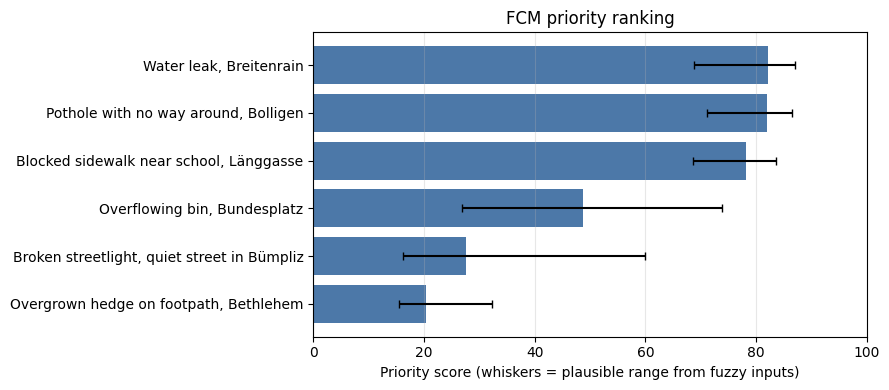

In [10]:
res = {k: m.assess(t, W) for k, t in reports.items()}
order = sorted(res, key=lambda k: res[k]["score"])
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(order))
ax.barh(y, [100 * res[k]["score"] for k in order], color="#4c78a8")
ax.errorbar([100 * res[k]["score"] for k in order], y,
            xerr=[[100 * (res[k]["score"] - res[k]["low"]) for k in order],
                  [100 * (res[k]["high"] - res[k]["score"]) for k in order]],
            fmt="none", ecolor="black", capsize=3)
ax.set_yticks(y); ax.set_yticklabels(order); ax.set_xlim(0, 100)
ax.set_xlabel("Priority score (whiskers = plausible range from fuzzy inputs)")
ax.set_title("FCM priority ranking"); ax.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

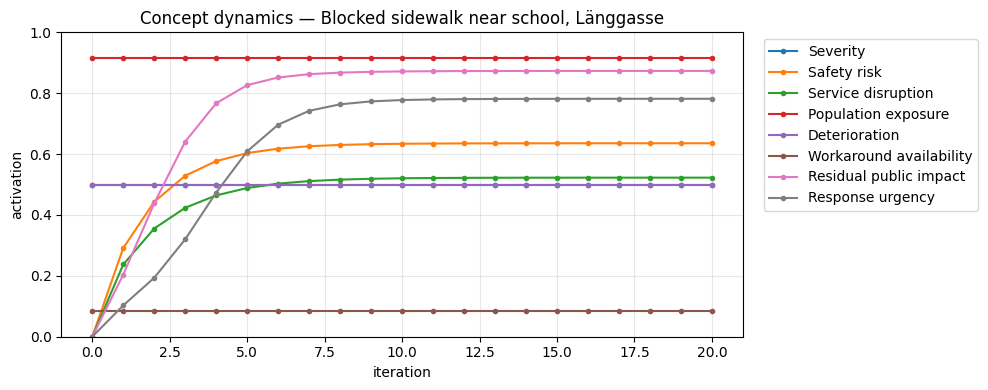

In [11]:
name = "Blocked sidewalk near school, Länggasse"
traj = res[name]["trajectory"].rename(columns=m.LABELS)
ax = traj.plot(figsize=(10, 4), marker=".")
ax.set_title(f"Concept dynamics — {name}"); ax.set_xlabel("iteration"); ax.set_ylabel("activation")
ax.set_ylim(0, 1); ax.grid(alpha=.3); plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

## 7. Explanation: which inputs drive a report's priority?

For each input we replace its term with *medium* and measure how much the score changes.

In [12]:
effects = pd.DataFrame({k: m.input_effects(t, W) * 100 for k, t in reports.items()}).T.round(1)
effects.columns = [m.LABELS[c] for c in effects.columns]
effects

,Deterioration,Population exposure,Severity,Workaround availability
"Pothole with no way around, Bolligen",5.3,0.0,7.7,3.5
"Overflowing bin, Bundesplatz",0.0,23.7,-21.8,-9.8
"Broken streetlight, quiet street in Bümpliz",-11.2,-17.5,0.0,4.3
"Blocked sidewalk near school, Länggasse",0.0,13.4,0.0,3.7
"Water leak, Breitenrain",11.3,0.0,10.4,0.0
"Overgrown hedge on footpath, Bethlehem",0.0,-4.8,-7.0,-1.8


## 8. Sensitivity analysis of the weights

The weights are expert judgements, so we test how much the ranking depends on them: every non-zero
weight is perturbed at random by ±0.10 (and ±0.20), 300 times, and the queue is re-ranked.
A mean Spearman ρ close to 1 means the ranking is robust.

In [13]:
for noise in (0.10, 0.20):
    rb = m.robustness(reports, W, noise=noise, n=300)
    print(f"noise ±{noise:.2f}: mean Spearman ρ = {rb['spearman'].mean():.3f}, "
          f"min = {rb['spearman'].min():.3f}, identical ranking in {np.mean(rb['spearman'] > 0.9999):.0%} of runs")
    display((rb["same_rank_share"] * 100).round(0).rename("% runs keeping its rank").to_frame())

noise ±0.10: mean Spearman ρ = 0.980, min = 0.943, identical ranking in 65% of runs


,% runs keeping its rank
"Pothole with no way around, Bolligen",65.0
"Overflowing bin, Bundesplatz",100.0
"Broken streetlight, quiet street in Bümpliz",100.0
"Blocked sidewalk near school, Länggasse",100.0
"Water leak, Breitenrain",65.0
"Overgrown hedge on footpath, Bethlehem",100.0


noise ±0.20: mean Spearman ρ = 0.967, min = 0.771, identical ranking in 61% of runs


,% runs keeping its rank
"Pothole with no way around, Bolligen",63.0
"Overflowing bin, Bundesplatz",99.0
"Broken streetlight, quiet street in Bümpliz",99.0
"Blocked sidewalk near school, Länggasse",92.0
"Water leak, Breitenrain",61.0
"Overgrown hedge on footpath, Bethlehem",100.0


## 9. Interpretation and limitations

- The weights are a **team draft** produced with a documented fuzzy elicitation procedure. They become
  stronger evidence once more experts (ideally from the City of Bern) fill in `expert_weights.csv`.
- Example reports are **synthetic**; the ranking is a demonstration, not an operational decision.
- **Validation idea:** Bern does not publish its reports (they arrive by web form on bern.ch; street
  lighting via ewb). Zurich publishes its *Züri wie neu* reports as open data. If that data includes
  closing dates, the category ranking produced by the model could be compared with how fast Zurich
  actually resolves each category.
- Safety-critical reports still need human verification; the model supports triage, it does not replace it.
- Safety risk feeds both Residual impact and Urgency (possible double counting); the sensitivity
  analysis shows how much this matters.

## References
- Kosko, B. (1986). Fuzzy cognitive maps. *Int. J. Man-Machine Studies* 24, 65–75.
- Stylios, C. D. & Groumpos, P. P. (2004). Modeling complex systems using fuzzy cognitive maps. *IEEE Trans. SMC — Part A* 34(1), 155–162.
- Papageorgiou, E. I. (2011). A new methodology for decisions in medical informatics using fuzzy cognitive maps based on fuzzy rule-extraction techniques. *Applied Soft Computing* 11(1), 500–513.
- Takagi, T. & Sugeno, M. (1985). Fuzzy identification of systems and its applications to modeling and control. *IEEE Trans. SMC* 15(1), 116–132.
- Zheng, Y., Capra, L., Wolfson, O. & Yang, H. (2014). Urban computing: concepts, methodologies, and applications. *ACM TIST* 5(3).